In [1]:
import torch
from torchvision import datasets, transforms
from torch.utils import data
from torch import nn
import matplotlib.pyplot as plt
batch_size=256
lr=0.9
epoch=20


In [2]:
def data_maker():
    transform = transforms.ToTensor()
    """
    transform = transforms.Compose([
        transforms.Resize((12, 12)),
        transforms.ToTensor()
    ])
    """

    train_dataset = datasets.FashionMNIST(
        root='../data',
        train=True,
        transform=transform,
        download=True
    )

    test_dataset = datasets.FashionMNIST(
        root='../data',
        train=False,
        transform=transform,
        download=True
    )
    return train_dataset,test_dataset

In [3]:
def data_loader(data_array,batch_size,flag):
    return data.DataLoader(data_array,batch_size,shuffle=flag)


In [4]:
def net_maker():
    net = nn.Sequential(
    nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Conv2d(6, 16, kernel_size=5), nn.Sigmoid(),
    nn.AvgPool2d(kernel_size=2, stride=2),
    nn.Flatten(),
    nn.Linear(16 * 5 * 5, 120), nn.Sigmoid(),
    nn.Linear(120, 84), nn.Sigmoid(),
    nn.Linear(84, 10))
    return net

In [5]:
def init(m):
    if isinstance(m,nn.Linear) or isinstance(m,nn.Conv2d):
        nn.init.xavier_uniform_(m.weight)
    

In [6]:
train_dataset,test_dataset=data_maker()
train_iter=data_loader(train_dataset,batch_size,True)
test_iter=data_loader(test_dataset,batch_size,False)
net=net_maker().to("cuda")
net.apply(init)

loss=nn.CrossEntropyLoss()

trainer=torch.optim.SGD(net.parameters(),lr=lr)


torch.Size([256, 1, 28, 28])
torch.Size([1, 28, 28])
3


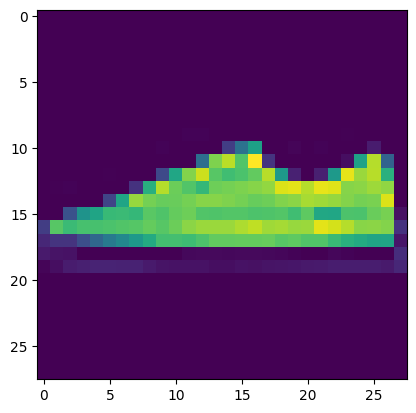

In [7]:
X, y = next(iter(train_iter))
print(X.size())

# 取一张图片
image = X[0]
print(X[0].size())
print(X[0].dim())

# 显示灰度图
plt.imshow(image.squeeze())

# 显示
plt.show()

In [8]:
for i in range(epoch):
    net.train()
    for x,y in train_iter:
        x=x.to("cuda")
        y=y.to("cuda")
        trainer.zero_grad()
        l=loss(net(x),y)
        l.backward()
        trainer.step()
    net.eval()
    train_acc=0
    test_acc=0
    train_loss=0.0
    test_loss=0.0
    train_count=0
    test_count=0
    with torch.no_grad():
        for x,y in train_iter:
            x=x.to("cuda")
            y=y.to("cuda")
            logit=net(x)
            train_count+=y.size(0)
            l=loss(logit,y)
            train_loss+=l*y.size(0)
            train_acc+=(logit.argmax(dim=1)==y).sum().item()
        print(f"第{i+1}轮的训练loss：{train_loss/train_count:.5f},训练准确率：{train_acc/train_count}")
        for x,y in test_iter:
            x=x.to("cuda")
            y=y.to("cuda")
            logit=net(x)
            test_count+=y.size(0)
            l=loss(logit,y)
            test_loss+=l*y.size(0)
            test_acc+=(logit.argmax(dim=1)==y).sum().item()
        print(f"第{i+1}轮的测试loss：{test_loss/test_count:.5f},测试准确率：{test_acc/test_count}")



第1轮的训练loss：2.30294,训练准确率：0.1
第1轮的测试loss：2.30296,测试准确率：0.1
第2轮的训练loss：0.91195,训练准确率：0.6664
第2轮的测试loss：0.92703,测试准确率：0.6628
第3轮的训练loss：0.82628,训练准确率：0.6928666666666666
第3轮的测试loss：0.85128,测试准确率：0.6851
第4轮的训练loss：0.65389,训练准确率：0.7370333333333333
第4轮的测试loss：0.67206,测试准确率：0.7308
第5轮的训练loss：0.64740,训练准确率：0.7577333333333334
第5轮的测试loss：0.66888,测试准确率：0.7523
第6轮的训练loss：0.57937,训练准确率：0.7747166666666667
第6轮的测试loss：0.60663,测试准确率：0.7615
第7轮的训练loss：0.62010,训练准确率：0.7736
第7轮的测试loss：0.65489,测试准确率：0.7611
第8轮的训练loss：0.49502,训练准确率：0.8122666666666667
第8轮的测试loss：0.52231,测试准确率：0.8004
第9轮的训练loss：0.46457,训练准确率：0.8273
第9轮的测试loss：0.49196,测试准确率：0.8185
第10轮的训练loss：0.50025,训练准确率：0.8112333333333334
第10轮的测试loss：0.52917,测试准确率：0.7975
第11轮的训练loss：0.47045,训练准确率：0.81875
第11轮的测试loss：0.49652,测试准确率：0.809
第12轮的训练loss：0.42859,训练准确率：0.8425
第12轮的测试loss：0.45667,测试准确率：0.8314
第13轮的训练loss：0.44950,训练准确率：0.8308666666666666
第13轮的测试loss：0.47946,测试准确率：0.8196
第14轮的训练loss：0.42682,训练准确率：0.8390666666666666
第14轮的测试loss：0.45972,测试准确率：0.8291
第15轮

In [9]:
torch.save(net.state_dict(),'Lenet_data')
net2=net_maker().to("cuda")
state=torch.load('Lenet_data')
net2.load_state_dict(state)
net2.eval()
train_acc=0
test_acc=0
train_loss=0.0
test_loss=0.0
train_count=0
test_count=0
with torch.no_grad():
    for x,y in train_iter:
        x=x.to("cuda")
        y=y.to("cuda")
        logit=net2(x)
        train_count+=y.size(0)
        l=loss(logit,y)
        train_loss+=l*y.size(0)
        train_acc+=(logit.argmax(dim=1)==y).sum().item()
    print(f"第{i+1}轮的训练loss：{train_loss/train_count:.5f},训练准确率：{train_acc/train_count}")
    for x,y in test_iter:
        x=x.to("cuda")
        y=y.to("cuda")
        logit=net2(x)
        test_count+=y.size(0)
        l=loss(logit,y)
        test_loss+=l*y.size(0)
        test_acc+=(logit.argmax(dim=1)==y).sum().item()
    print(f"第{i+1}轮的测试loss：{test_loss/test_count:.5f},测试准确率：{test_acc/test_count}")

第20轮的训练loss：0.37507,训练准确率：0.8574166666666667
第20轮的测试loss：0.40890,测试准确率：0.847
